Time dependant schrodinger equation is: i $\hbar$ d $\psi$ (t)/dt = H $\psi$ (t)

The time dependent H(t)= H_0 + H_1(t)

Where H_0 is the transmon hamilton from part 1, H_1(t) is 

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import linalg as sla
from scipy import sparse as sp
import scipy.integrate as spi
#I use the number basis this time because it is easier to work with
def H_number(N, Ec, Ej):
    M=len(N)-1 # since the upper and lower diagonal has 1 less element than the diagonal
    K= 4*Ec*np.diag(N**2,0)
    V= -Ej/2 * (np.diag(np.ones(M),1)+np.diag(np.ones(M),-1))
    H=sp.csr_matrix(K+V)
    return(H) 

In [18]:
N=np.arange(-10,11,1) # the number of Cooper pairs from -10 to 10
E_j, E_c =1, 1/50 # same as before
H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
E,U= sla.eigsh(H_num, k=3, which='SA') # the eigenvalues and eigenvectors in n basis

In [19]:
H_0= np.diag(E,0) - E[0] * np.eye(3) # the diagonal matrix of the eigenvalues with the ground state energy subtracted so that the ground state energy is zero. This is done so that the energies are measured relative to the ground state energy.

In [20]:
A= U.T @ np.diag(N) @ U #the coupling term between the different states
def H_drive(t,omega, w,A):
    return(omega*np.sin(w*t)*A)

In [21]:
def H_time(t,H0,A,omega,w): #the time dependent hamiltonian
    return(H0+H_drive(t,omega,w,A))

In [22]:
w=E[1]-E[0] # the frequency of the drive   
omega=0.01 # the amplitude of the drive must be smaller than E_c
H_t=H_time(0.75,H_0,A,omega,w)
print(H_t) #test

[[6.04085251e-18 3.04933705e-03 7.65573264e-19]
 [3.04933705e-03 3.78838378e-01 4.17755258e-03]
 [5.69111964e-19 4.17755258e-03 7.34692296e-01]]


In [23]:
def rk4solve(f,y0,x0,h,xmax):
    ycoor=[y0] #starting value of y
    xcoor=[x0] #starting value of x
    while (xcoor[-1]<=xmax-h):
        x,y=xcoor[-1], ycoor[-1] # get the last values of x and y
        k1=f(x,y) #calculate k1 using the function f(x,y)
        k2=f( x + 1/2 *h, y + h/2 *k1) #calculate k2 using the function f(x,y) and the values of x and y
        k3=f(x+h/2,y+h/2 * k2) #calculate k3 
        k4=f(x+h,y+k3*h) #calculate k4 there was missing a h in the last term on k3 on the slides
        y=y+h/6*(k1+2*k2+2*k3+k4) # update y using the Runge-Kutta method
        xcoor.append(x+h),ycoor.append(y) # each element of the list ycoor becomes a row in the array Y, so Y will be a 2D array with each row corresponding to a time step and each column corresponding to a variable in the system of ODEs.
    return(np.array(xcoor),np.array(ycoor)) #return the x and y coordinates as numpy arrays 

In [24]:
def f(t, c):
    return -1j * H_time(t, H_0, A, omega, w) @ c
c0 = np.array([1, 0, 0], dtype=complex) # starting in the ground state, zero in the first and second excited states.


In [25]:
t, C = rk4solve(f, c0, 0, 0.005, 5000) # solve the system of ODEs using the Runge-Kutta method with a time step of 0.005 and a maximum time of 5000
#t is the x coordinates and C is the y coordinates. The timme of course starts at 0 and the state starts in ground state

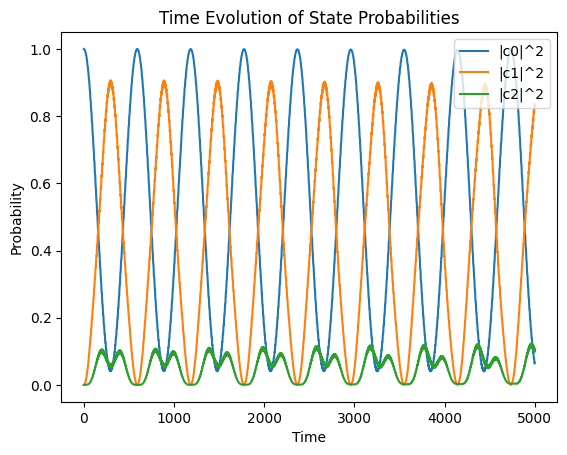

In [26]:
plt.plot(t, np.abs(C[:, 0])**2, label='|c0|^2')
plt.plot(t, np.abs(C[:, 1])**2, label='|c1|^2')
plt.plot(t, np.abs(C[:, 2])**2, label='|c2|^2')
plt.xlabel('Time')
plt.ylabel('Probability')
plt.title('Time Evolution of State Probabilities')
plt.legend(loc='upper right')
plt.show()

In [27]:
sol = spi.solve_ivp(f, (0, 5000), c0, method='RK45',rtol=1e-8, atol=1e-8, t_eval=t)

In [28]:
t_s, C_s = sol.t, sol.y.T  # Transpose sol.y to match the shape of C from rk4solve

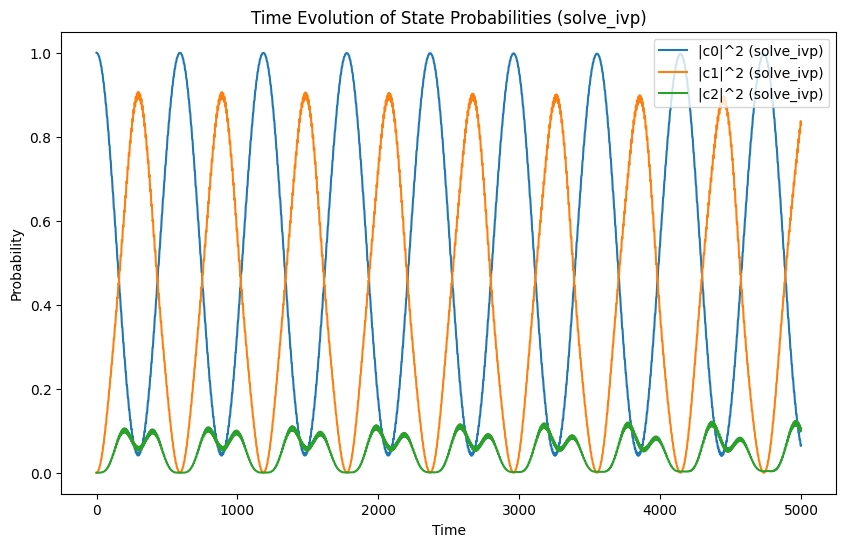

In [29]:
plt.figure(figsize=(10, 6)) 
plt.plot(t_s, np.abs(C_s[:, 0])**2, label='|c0|^2 (solve_ivp)')
plt.plot(t_s, np.abs(C_s[:, 1])**2, label='|c1|^2 (solve_ivp)')
plt.plot(t_s, np.abs(C_s[:, 2])**2, label='|c2|^2 (solve_ivp)')
plt.xlabel('Time')
plt.ylabel('Probability')
plt.title('Time Evolution of State Probabilities (solve_ivp)')
plt.legend(loc='upper right')
plt.show()

Gives the exact same plot so my RK4 must be valid

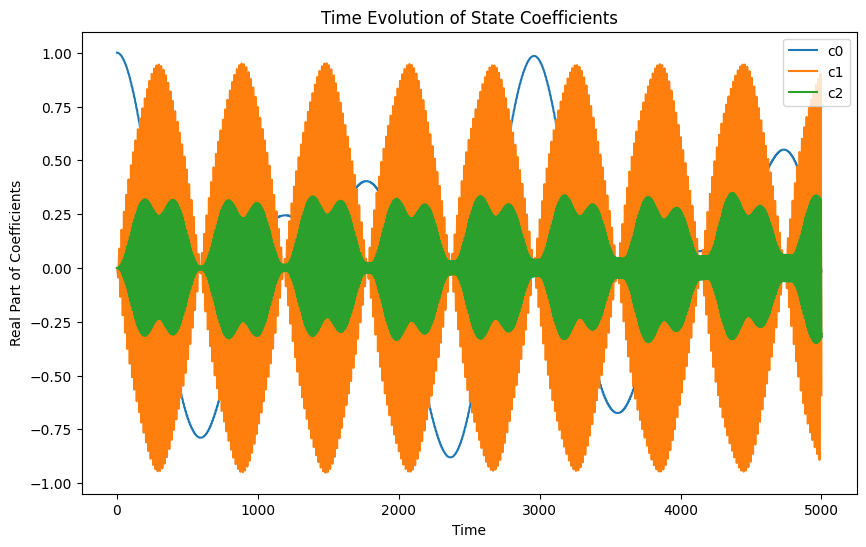

In [30]:
plt.figure(figsize=(10, 6))
plt.plot(t, C[:, 0].real, label='c0')
plt.plot(t, C[:, 1].real, label='c1')
plt.plot(t, C[:, 2].real, label='c2')
plt.xlabel('Time')
plt.ylabel('Real Part of Coefficients')
plt.title('Time Evolution of State Coefficients')
plt.legend()
plt.show()

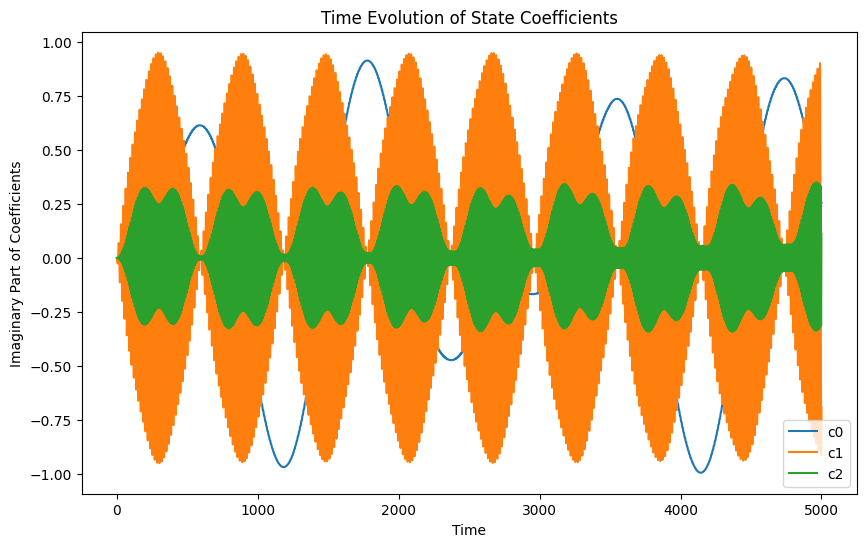

In [31]:
plt.figure(figsize=(10, 6))
plt.plot(t, C[:, 0].imag, label='c0')
plt.plot(t, C[:, 1].imag, label='c1')
plt.plot(t, C[:, 2].imag, label='c2')
plt.xlabel('Time')
plt.ylabel('Imaginary Part of Coefficients')
plt.title('Time Evolution of State Coefficients')
plt.legend()
plt.show()